<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: sans-serif;">


# یادگیری بدون نظارت (Unsupervised Learning)
## Unsupervised Algorithms

در این نوت‌بوک هفت موضوع اصلی یادگیری بدون نظارت را با توضیح کوتاه و مثال‌های عملی Python بررسی می‌کنیم.

**هدف کلی:** پیدا کردن ساختار، گروه‌ها، الگوها و نمونه‌های غیرعادی در داده‌هایی که معمولاً برچسب (Label) مشخصی ندارند.

### کتابخانه‌های موردنیاز

در صورت نصب نبودن کتابخانه‌ها، سلول زیر را اجرا کنید.


</div>

In [ ]:
%pip install -q numpy pandas matplotlib scikit-learn scipy

<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: sans-serif;">


## آماده‌سازی کتابخانه‌ها

در مثال‌ها از `scikit-learn` برای الگوریتم‌ها و ارزیابی، و از `matplotlib` برای نمایش نتایج استفاده می‌کنیم.


</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs, make_moons, load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.ensemble import IsolationForest

RANDOM_STATE = 42


<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: sans-serif;">


# 45. K-Means Clustering

## مفهوم

**K-Means** داده‌ها را به تعداد مشخصی خوشه (Cluster) تقسیم می‌کند. هر خوشه یک مرکز دارد که به آن **Centroid** می‌گوییم.

الگوریتم به‌صورت تکراری:
1. تعداد `K` مرکز اولیه را تعیین می‌کند.
2. هر نمونه را به نزدیک‌ترین مرکز نسبت می‌دهد.
3. مرکز هر خوشه را با میانگین نمونه‌های آن به‌روزرسانی می‌کند.
4. این مراحل تا همگرایی یا رسیدن به حداکثر تکرار ادامه پیدا می‌کنند.

**نکته‌ها:**
- باید تعداد خوشه‌ها (`n_clusters`) را مشخص کنیم.
- به مقیاس ویژگی‌ها حساس است؛ معمولاً قبل از اجرا از `StandardScaler` استفاده می‌کنیم.
- برای خوشه‌های تقریباً کروی و جدا از هم مناسب‌تر است و در برابر نقاط پرت حساسیت دارد.

## نمونه عملی

داده مصنوعی با سه گروه تولید می‌کنیم و K-Means را روی آن اجرا می‌کنیم.


</div>

Cluster counts:
0    200
1    200
2    200
Name: count, dtype: int64


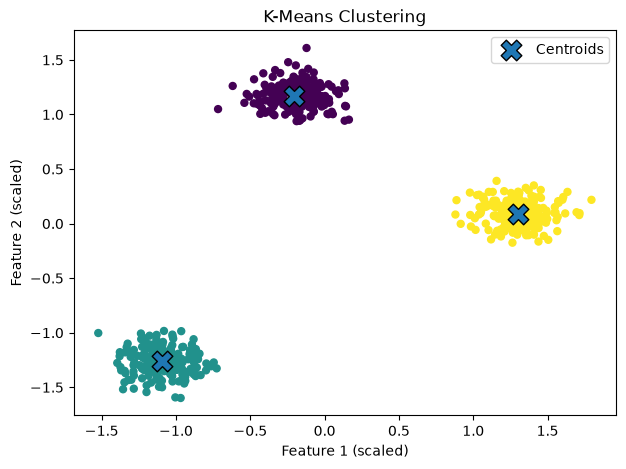

Inertia: 21.9


In [2]:
# Create a dataset with three natural groups
X, y_true = make_blobs(
    n_samples=600, centers=3, cluster_std=0.75, random_state=RANDOM_STATE
)

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Fit K-Means
kmeans = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE)
cluster_labels = kmeans.fit_predict(X_scaled)

print("Cluster counts:")
print(pd.Series(cluster_labels).value_counts().sort_index())

# Visualize clusters
plt.figure(figsize=(7, 5))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=cluster_labels, cmap="viridis", s=25)
plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker="X",
    s=220,
    edgecolor="black",
    label="Centroids",
)
plt.title("K-Means Clustering")
plt.xlabel("Feature 1 (scaled)")
plt.ylabel("Feature 2 (scaled)")
plt.legend()
plt.show()

print("Inertia:", round(kmeans.inertia_, 2))


<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: sans-serif;">


# 46. Hierarchical Clustering

## مفهوم

**Hierarchical Clustering** خوشه‌ها را به‌صورت سلسله‌مراتبی ایجاد می‌کند. در روش رایج **Agglomerative**، ابتدا هر نمونه یک خوشه مستقل است و سپس نزدیک‌ترین خوشه‌ها مرحله‌به‌مرحله با هم ادغام می‌شوند.

روش‌های متداول تعیین فاصله بین خوشه‌ها:
- `single`: کمترین فاصله بین اعضای دو خوشه
- `complete`: بیشترین فاصله
- `average`: میانگین فاصله‌ها
- `ward`: ادغام خوشه‌هایی که افزایش واریانس درون‌خوشه‌ای را کمینه می‌کند

درخت ادغام‌ها را می‌توان با **Dendrogram** نمایش داد. در Scikit-learn، `AgglomerativeClustering` خوشه‌بندی را انجام می‌دهد؛ برای رسم Dendrogram می‌توان از SciPy استفاده کرد.

## نمونه عملی

از داده‌های قبلی استفاده می‌کنیم و آن‌ها را با روش Ward به سه خوشه تقسیم می‌کنیم.


</div>

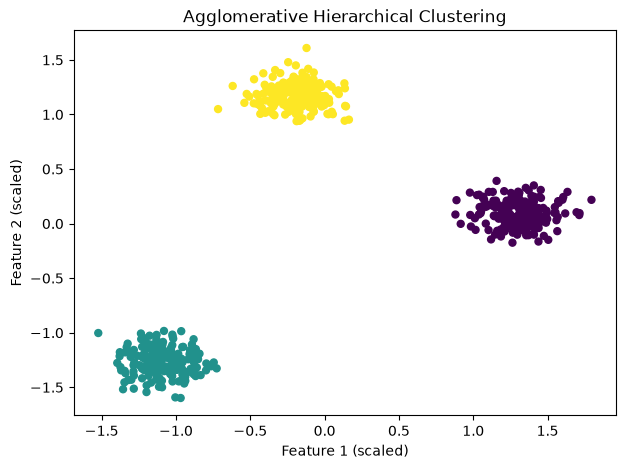

Cluster counts:
0    200
1    200
2    200
Name: count, dtype: int64


In [3]:
hierarchical = AgglomerativeClustering(n_clusters=3, linkage="ward")

hierarchical_labels = hierarchical.fit_predict(X_scaled)

plt.figure(figsize=(7, 5))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=hierarchical_labels, cmap="viridis", s=25)
plt.title("Agglomerative Hierarchical Clustering")
plt.xlabel("Feature 1 (scaled)")
plt.ylabel("Feature 2 (scaled)")
plt.show()

print("Cluster counts:")
print(pd.Series(hierarchical_labels).value_counts().sort_index())


<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: sans-serif;">


# 47. DBSCAN

## مفهوم

**DBSCAN** مخفف `Density-Based Spatial Clustering of Applications with Noise` است. این الگوریتم خوشه‌ها را بر اساس تراکم نقاط پیدا می‌کند و لازم نیست تعداد خوشه‌ها را از قبل مشخص کنیم.

دو پارامتر مهم:
- `eps`: شعاع همسایگی هر نقطه
- `min_samples`: حداقل تعداد نقاط لازم در همسایگی برای هسته (Core Point) محسوب شدن

DBSCAN نقاط را به سه دسته مفهومی تقسیم می‌کند:
- **Core:** همسایگی پرتراکمی دارد.
- **Border:** به یک نقطه Core نزدیک است، اما خودش Core نیست.
- **Noise:** به هیچ خوشه‌ای تعلق ندارد؛ در خروجی Scikit-learn با برچسب `-1` مشخص می‌شود.

**نکته‌ها:** به مقیاس ویژگی‌ها حساس است. انتخاب نامناسب `eps` و `min_samples` می‌تواند نتیجه را تغییر دهد. برای خوشه‌های با تراکم‌های متفاوت نیز ممکن است مناسب نباشد.

## نمونه عملی

داده‌های هلالی‌شکل تولید می‌کنیم؛ الگویی که K-Means معمولاً برای جداسازی آن دشوارتر است.


</div>

Number of clusters: 2
Number of noise points: 0


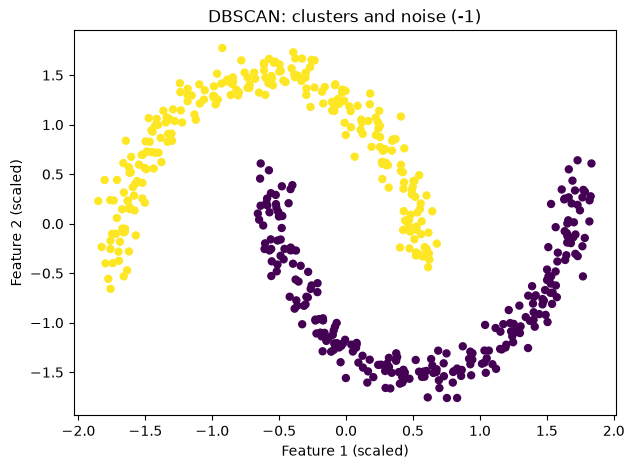

In [4]:
X_moons, _ = make_moons(n_samples=500, noise=0.06, random_state=RANDOM_STATE)

X_moons_scaled = StandardScaler().fit_transform(X_moons)

dbscan = DBSCAN(eps=0.25, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_moons_scaled)

n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = np.sum(dbscan_labels == -1)

print("Number of clusters:", n_clusters)
print("Number of noise points:", n_noise)

plt.figure(figsize=(7, 5))
plt.scatter(
    X_moons_scaled[:, 0], X_moons_scaled[:, 1], c=dbscan_labels, cmap="viridis", s=25
)
plt.title("DBSCAN: clusters and noise (-1)")
plt.xlabel("Feature 1 (scaled)")
plt.ylabel("Feature 2 (scaled)")
plt.show()


<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: sans-serif;">


# 48. Clustering Evaluation

## مفهوم

در خوشه‌بندی معمولاً برچسب واقعی نداریم؛ بنابراین ارزیابی همیشه ساده نیست. دو نوع معیار وجود دارد:

### معیارهای بدون برچسب واقعی (Internal Metrics)

- **Silhouette Score:** میزان نزدیک بودن هر نمونه به خوشه خودش در مقایسه با خوشه‌های دیگر را می‌سنجد. مقدار آن بین `-1` و `1` است؛ مقدار بالاتر معمولاً بهتر است.
- **Davies-Bouldin Index:** فشردگی درون خوشه‌ها و جدایی بین خوشه‌ها را بررسی می‌کند؛ مقدار کمتر معمولاً بهتر است.
- **Calinski-Harabasz Index:** نسبت پراکندگی بین خوشه‌ها به پراکندگی درون خوشه‌ها را می‌سنجد؛ مقدار بالاتر معمولاً بهتر است.

این معیارها را نباید بدون توجه به شکل داده و هدف مسئله، تنها معیار انتخاب مدل قرار داد. برای مثال Silhouette می‌تواند برای بعضی خوشه‌های غیرکروی تصویر کاملی ندهد.

### معیارهای با برچسب واقعی (External Metrics)

اگر برچسب واقعی در اختیار داشته باشیم، می‌توانیم از معیارهایی مثل `Adjusted Rand Index (ARI)` استفاده کنیم. در کاربرد بدون نظارت واقعی، این برچسب‌ها معمولاً فقط برای ارزیابی آزمایشی در دسترس‌اند، نه آموزش.

## نمونه عملی

چند مقدار K را در K-Means بررسی می‌کنیم و معیارهای داخلی را مقایسه می‌کنیم.


</div>

In [5]:
evaluation_rows = []

for k in range(2, 7):
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = model.fit_predict(X_scaled)

    evaluation_rows.append(
        {
            "K": k,
            "Inertia": model.inertia_,
            "Silhouette": silhouette_score(X_scaled, labels),
            "Davies-Bouldin": davies_bouldin_score(X_scaled, labels),
            "Calinski-Harabasz": calinski_harabasz_score(X_scaled, labels),
        }
    )

evaluation_df = pd.DataFrame(evaluation_rows)
display(evaluation_df.round(3))

# Optional external evaluation: y_true is available because this is synthetic data.
final_kmeans_labels = KMeans(
    n_clusters=3, n_init=10, random_state=RANDOM_STATE
).fit_predict(X_scaled)

print(
    "Adjusted Rand Index:", round(adjusted_rand_score(y_true, final_kmeans_labels), 3)
)


,K,Inertia,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,2,365.689,0.707,0.441,1364.321
1,3,21.896,0.883,0.164,16060.978
2,4,18.796,0.706,0.618,12485.033
3,5,15.901,0.538,0.869,11077.099
4,6,13.153,0.351,1.072,10719.567


Adjusted Rand Index: 1.0


<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: sans-serif;">


# 49. PCA — Algorithm and Practical Use

## مفهوم

**Principal Component Analysis (PCA)** یک روش کاهش بُعد (Dimensionality Reduction) است. PCA ویژگی‌های اصلی را به مجموعه‌ای کوچک‌تر از متغیرهای جدید به نام **Principal Components** تبدیل می‌کند.

این مؤلفه‌ها:
- ترکیب خطی ویژگی‌های اولیه‌اند.
- با یکدیگر نامرتبط (Orthogonal) هستند.
- به‌ترتیب بیشترین واریانس ممکن در داده را توضیح می‌دهند.

### کاربردها
- کاهش تعداد ویژگی‌ها
- فشرده‌سازی داده
- کمک به نمایش داده‌های چندبعدی در ۲ یا ۳ بُعد
- گاهی کاهش نویز و هزینه محاسباتی

**نکته مهم:** PCA به مقیاس ویژگی‌ها حساس است؛ بنابراین معمولاً ابتدا داده‌ها را Standardize می‌کنیم. همچنین بیشترین واریانس الزاماً به معنی بیشترین اطلاعات مرتبط با هدف مسئله نیست.

## نمونه عملی

دیتاست Breast Cancer دارای ۳۰ ویژگی است. آن را به دو مؤلفه کاهش می‌دهیم و نسبت واریانس توضیح‌داده‌شده را بررسی می‌کنیم.


</div>

Original shape: (569, 30)
Reduced shape: (569, 2)
Explained variance ratio: [0.443 0.19 ]
Total explained variance: 0.632


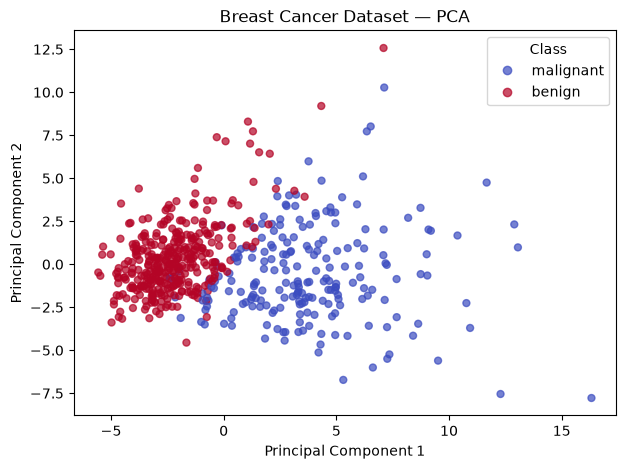

In [6]:
cancer = load_breast_cancer()
X_cancer = cancer.data
y_cancer = cancer.target

X_cancer_scaled = StandardScaler().fit_transform(X_cancer)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_cancer_scaled)

print("Original shape:", X_cancer.shape)
print("Reduced shape:", X_pca.shape)
print("Explained variance ratio:", np.round(pca.explained_variance_ratio_, 3))
print("Total explained variance:", round(pca.explained_variance_ratio_.sum(), 3))

plt.figure(figsize=(7, 5))
scatter = plt.scatter(
    X_pca[:, 0], X_pca[:, 1], c=y_cancer, cmap="coolwarm", alpha=0.7, s=25
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Breast Cancer Dataset — PCA")
plt.legend(
    handles=scatter.legend_elements()[0],
    labels=list(cancer.target_names),
    title="Class",
)
plt.show()


<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: sans-serif;">


# 50. t-SNE — Visualization and Limitations

## مفهوم

**t-distributed Stochastic Neighbor Embedding (t-SNE)** روشی برای کاهش بُعد است که بیشتر برای نمایش بصری داده‌های چندبعدی در ۲ یا ۳ بُعد استفاده می‌شود.

این روش تلاش می‌کند همسایگی‌های محلی (Local Neighborhoods) را در فضای کم‌بُعد حفظ کند؛ یعنی نمونه‌هایی که در فضای اصلی نزدیک‌اند، تا حد امکان در نمایش جدید نیز نزدیک باقی بمانند.

### پارامتر مهم: `perplexity`

`perplexity` تقریباً میزان همسایگی مورد توجه الگوریتم را کنترل می‌کند. مقدار مناسب به اندازه و ساختار داده وابسته است.

### محدودیت‌ها
- فاصله‌ها و اندازه خوشه‌های جدا از هم در نمودار را نباید تفسیر قطعی کرد.
- نتیجه می‌تواند به تنظیم پارامترها و مقداردهی اولیه وابسته باشد.
- برای حفظ ساختار کلی و فاصله‌های سراسری (Global Structure) طراحی نشده است.
- معمولاً برای Visualization مناسب‌تر از ساخت Feature برای مدل نهایی است.
- اجرای آن می‌تواند پرهزینه باشد.

## نمونه عملی

برای جلوگیری از اجرای سنگین، از ۵۰۰ نمونه دیتاست Breast Cancer استفاده می‌کنیم. ابتدا PCA برای کاهش اولیه به ۲۰ بُعد و سپس t-SNE برای نمایش دوبعدی اجرا می‌شود.


</div>

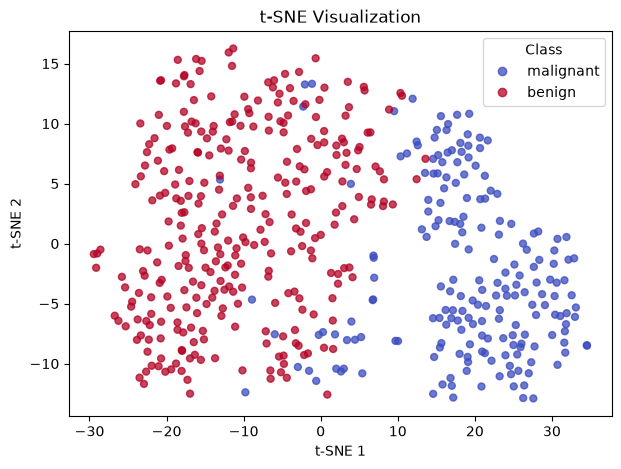

In [7]:
# Select a reproducible subset
rng = np.random.default_rng(RANDOM_STATE)
sample_indices = rng.choice(len(X_cancer_scaled), size=500, replace=False)

X_sample = X_cancer_scaled[sample_indices]
y_sample = y_cancer[sample_indices]

# PCA pre-reduction can make t-SNE faster on higher-dimensional data
X_preduced = PCA(n_components=20, random_state=RANDOM_STATE).fit_transform(X_sample)

tsne = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    random_state=RANDOM_STATE,
)

X_tsne = tsne.fit_transform(X_preduced)

plt.figure(figsize=(7, 5))
scatter = plt.scatter(
    X_tsne[:, 0], X_tsne[:, 1], c=y_sample, cmap="coolwarm", alpha=0.75, s=25
)
plt.title("t-SNE Visualization")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.legend(
    handles=scatter.legend_elements()[0],
    labels=list(cancer.target_names),
    title="Class",
)
plt.show()


<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: sans-serif;">


# 51. Anomaly Detection — Fundamentals

## مفهوم

**Anomaly Detection** یا تشخیص ناهنجاری، شناسایی نمونه‌هایی است که رفتار یا ویژگی‌هایشان با الگوی غالب داده تفاوت قابل‌توجهی دارد.

مثال‌های کاربردی:
- تشخیص تراکنش بانکی مشکوک
- شناسایی خطای غیرعادی در سنسورهای صنعتی
- تشخیص رفتار غیرمعمول در ترافیک شبکه
- شناسایی خطا در داده‌های عملیاتی

### روش‌های رایج

- **Isolation Forest:** نمونه‌های غیرعادی را با استفاده از درخت‌های تصادفی معمولاً سریع‌تر از نمونه‌های عادی جدا می‌کند.
- **Local Outlier Factor (LOF):** چگالی محلی یک نمونه را با همسایه‌هایش مقایسه می‌کند.
- **One-Class SVM:** مرزی پیرامون ناحیه داده‌های عادی یاد می‌گیرد.

در بسیاری از مسائل، داده‌های Anomaly برچسب ندارند یا بسیار کم‌اند؛ به همین دلیل ارزیابی این مدل‌ها دشوارتر است.

### Isolation Forest در Scikit-learn

- خروجی `predict`: مقدار `1` برای نمونه عادی و `-1` برای ناهنجاری.
- پارامتر `contamination`: برآورد نسبت ناهنجاری‌ها در داده؛ این مقدار روی آستانه تصمیم اثر می‌گذارد.

## نمونه عملی

داده‌ای مصنوعی با نقاط پرت تولید می‌کنیم و با Isolation Forest آن‌ها را شناسایی می‌کنیم.


</div>

Predicted normal: 498
Predicted anomalies: 32


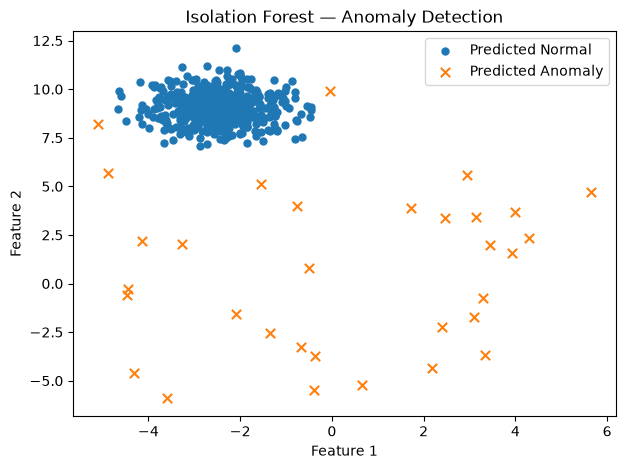

In [8]:
# Generate mostly normal observations
X_normal, _ = make_blobs(
    n_samples=500, centers=1, cluster_std=0.8, random_state=RANDOM_STATE
)

# Add artificial anomalies far from the main group
rng = np.random.default_rng(RANDOM_STATE)
X_anomalies = rng.uniform(low=-6, high=6, size=(30, 2))

X_anomaly_data = np.vstack([X_normal, X_anomalies])

# Fit Isolation Forest
isolation_forest = IsolationForest(
    n_estimators=200, contamination=0.06, random_state=RANDOM_STATE
)

predictions = isolation_forest.fit_predict(X_anomaly_data)

normal_mask = predictions == 1
anomaly_mask = predictions == -1

print("Predicted normal:", normal_mask.sum())
print("Predicted anomalies:", anomaly_mask.sum())

# Visualize results
plt.figure(figsize=(7, 5))
plt.scatter(
    X_anomaly_data[normal_mask, 0],
    X_anomaly_data[normal_mask, 1],
    label="Predicted Normal",
    s=25,
)
plt.scatter(
    X_anomaly_data[anomaly_mask, 0],
    X_anomaly_data[anomaly_mask, 1],
    label="Predicted Anomaly",
    marker="x",
    s=45,
)
plt.title("Isolation Forest — Anomaly Detection")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()


<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: sans-serif;">


# جمع‌بندی مسیر و انتخاب الگوریتم

| موضوع | کاربرد اصلی | نکته کلیدی |
|---|---|---|
| K-Means | تقسیم داده به K خوشه | تعداد خوشه را تعیین می‌کنیم |
| Hierarchical | ساخت خوشه‌های سلسله‌مراتبی | امکان بررسی ساختار ادغام خوشه‌ها |
| DBSCAN | خوشه‌بندی مبتنی بر تراکم | تشخیص Noise و عدم نیاز به تعیین K |
| Clustering Evaluation | سنجش کیفیت خوشه‌ها | Silhouette و معیارهای دیگر |
| PCA | کاهش بُعد | حفظ بیشترین واریانس ممکن |
| t-SNE | نمایش بصری داده‌های چندبعدی | تمرکز بر ساختار محلی |
| Anomaly Detection | شناسایی نمونه‌های غیرعادی | خروجی الزاماً به معنی خطای واقعی نیست |

## منابع رسمی

- [Scikit-learn — Clustering](https://scikit-learn.org/stable/modules/clustering.html)
- [KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html)
- [AgglomerativeClustering](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.AgglomerativeClustering.html)
- [DBSCAN](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
- [Clustering performance evaluation](https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation)
- [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html)
- [TSNE](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html)
- [IsolationForest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html)


</div>